# FL-BENCH-004.11 — Broader tuning: six-parameter random search vs lr/mu grid

*Epic EPIC-001 · story fl_bench_004 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Test whether tuning more than learning rate and FedProx mu (batch size, local epochs, hidden width, SCAFFOLD server step) changes conclusions, on synthetic data and on the four natural sites.

## 2. Scientific background
Hyper-parameter sensitivity can reverse algorithm rankings in FL benchmarks [li2021niid, hsu2019]; random search is a standard budget-matched alternative to grids.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does a 24-configuration random search over six parameters beat the lr/mu grid on test F1?
- **RQ2.** Does it change which algorithm is best?

## 4. Hypotheses
- **H1.** Gains over the grid are small relative to seed variability.

## 5. Mathematical formulation
Same 24 draws for every algorithm; selection by mean validation F1 (tie: lower validation loss) on 25% of TRAIN; three settings compared on the untouched test set: default, grid (lr[,mu]), random (6 parameters). Paired Wilcoxon / t by seed (synthetic, 10) or split (heart, 5).

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_bench_004"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_bench_004


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "search_space": {
  "lr": "log-uniform [0.005, 0.8]",
  "mu": "log-uniform [1e-3, 1] (FedProx)",
  "batch_size": [
   16,
   32,
   64
  ],
  "local_epochs": [
   1,
   2,
   3,
   5
  ],
  "hidden": [
   16,
   32,
   64
  ],
  "server_lr": "[0.5, 1, 1.5] (SCAFFOLD)"
 },
 "n_random_configs": 24,
 "grid_configs": {
  "fedavg_like": 7,
  "fedprox": 42
 },
 "rounds": 30,
 "tune_seeds": [
  100,
  101
 ],
 "eval_seeds": [
  0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9
 ],
 "natural_site_splits": [
  0,
  1,
  2,
  3,
  4
 ],
 "selection": "mean validation F1 on 25% of TRAIN; test untouched",
 "compute_note": "local_epochs and hidden width change per-round compute, so budgets are matched in number of configurations, NOT in FLOPs"
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`experiments/ext2.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.pipelines.experiments.ext2 import sample_configs, _algo_cfg
c = sample_configs(24, 7); assert c == sample_configs(24, 7)
print(len(c), "configs; lr range", round(min(x["lr"] for x in c), 4), "-", round(max(x["lr"] for x in c), 3), "| epochs used", sorted({x["local_epochs"] for x in c}))
print("fedavg config ignores mu/server_lr:", _algo_cfg(c[0], "fedavg"))
assert all(0.005 <= x["lr"] <= 0.8 and 1e-3 <= x["mu"] <= 1 for x in c)

24 configs; lr range 0.0053 - 0.782 | epochs used [1, 2, 3, 5]
fedavg config ignores mu/server_lr: {'lr': 0.11933158616708683, 'mu': 0.0, 'batch_size': 32, 'local_epochs': 5, 'hidden': 64, 'server_lr': 1.0}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-BENCH-004.11` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_4_11_runs.csv')
show_csv('task_4_11_selected_configs.csv')

,dataset,algo,setting,rep,acc,f1,auc,loss,recall,specificity,bacc
0,synthetic,fedavg,default,0,0.8897,0.8547,0.9561,0.2683,0.8066,0.9456,0.8761
1,synthetic,fedavg,default,1,0.9019,0.8734,0.9615,0.2573,0.8412,0.9428,0.8920
2,synthetic,fedavg,default,2,0.8497,0.7851,0.9405,0.3447,0.6823,0.9624,0.8223
3,synthetic,fedavg,default,3,0.8461,0.7753,0.9399,0.3523,0.6602,0.9712,0.8157
4,synthetic,fedavg,default,4,0.8994,0.8683,0.9606,0.2560,0.8239,0.9503,0.8871
5,synthetic,fedavg,default,5,0.8553,0.7888,0.9547,0.3335,0.6720,0.9786,0.8253
6,synthetic,fedavg,default,6,0.9022,0.8728,0.9603,0.2534,0.8343,0.9480,0.8911
7,synthetic,fedavg,default,7,0.8853,0.8524,0.9518,0.2753,0.8239,0.9266,0.8752
8,synthetic,fedavg,default,8,0.8942,0.8678,0.9554,0.2673,0.8633,0.9150,0.8891
9,synthetic,fedavg,default,9,0.9150,0.8919,0.9688,0.2270,0.8715,0.9442,0.9079


,dataset,algo,method,lr,mu,local_epochs,batch_size,hidden,server_lr,split
0,synthetic,fedavg,"grid(lr,mu)",0.8000,0.0000,2.0,NaN,NaN,NaN,NaN
1,synthetic,fedavg,random(6 params),0.7819,0.0000,3.0,64.0,32.0,1.0,NaN
2,synthetic,fedprox,"grid(lr,mu)",0.4000,0.0100,2.0,NaN,NaN,NaN,NaN
3,synthetic,fedprox,random(6 params),0.3150,0.0138,5.0,32.0,32.0,1.0,NaN
4,synthetic,scaffold,"grid(lr,mu)",0.1000,0.0000,2.0,NaN,NaN,NaN,NaN
5,synthetic,scaffold,random(6 params),0.0194,0.0000,3.0,16.0,64.0,1.5,NaN
6,synthetic,fednova,"grid(lr,mu)",0.8000,0.0000,2.0,NaN,NaN,NaN,NaN
7,synthetic,fednova,random(6 params),0.1078,0.0000,3.0,32.0,64.0,1.0,NaN
8,heart-4sites,fedavg,"grid(lr,mu)",0.1000,0.0000,NaN,NaN,NaN,NaN,0.0
9,heart-4sites,fedavg,random(6 params),0.2856,0.0000,2.0,64.0,32.0,1.0,0.0


## 12. Metrics collection
Metric definitions: test acc/F1/AUC for default, grid and random settings.

In [8]:
show_csv('task_4_11_summary.csv', 30)

,dataset,algo,setting,n,acc,acc_ci,f1,f1_ci,auc,auc_ci
0,synthetic,fedavg,default,10,0.8839,"[0.8663, 0.9015]",0.8431,"[0.8124, 0.8737]",0.9550,"[0.9485, 0.9615]"
1,synthetic,fedavg,grid,10,0.8831,"[0.8582, 0.9080]",0.8481,"[0.8128, 0.8834]",0.9472,"[0.9266, 0.9678]"
2,synthetic,fedavg,random,10,0.8910,"[0.8823, 0.8996]",0.8589,"[0.8449, 0.8730]",0.9558,"[0.9525, 0.9592]"
3,synthetic,fedprox,default,10,0.8808,"[0.8632, 0.8985]",0.8391,"[0.8088, 0.8693]",0.9526,"[0.9448, 0.9605]"
4,synthetic,fedprox,grid,10,0.8914,"[0.8822, 0.9006]",0.8581,"[0.8425, 0.8736]",0.9567,"[0.9529, 0.9605]"
5,synthetic,fedprox,random,10,0.8892,"[0.8838, 0.8946]",0.8554,"[0.8461, 0.8648]",0.9552,"[0.9532, 0.9573]"
6,synthetic,scaffold,default,10,0.8986,"[0.8868, 0.9103]",0.8729,"[0.8606, 0.8852]",0.9593,"[0.9529, 0.9656]"
7,synthetic,scaffold,grid,10,0.8225,"[0.7256, 0.9194]",0.8012,"[0.7093, 0.8931]",0.8684,"[0.7586, 0.9782]"
8,synthetic,scaffold,random,10,0.8613,"[0.7889, 0.9337]",0.8143,"[0.6994, 0.9293]",0.9006,"[0.8044, 0.9968]"
9,synthetic,fednova,default,10,0.8948,"[0.8836, 0.9060]",0.8637,"[0.8471, 0.8803]",0.9592,"[0.9547, 0.9638]"


## 13. Statistical analysis
Paired tests for random-grid, random-default, grid-default; uncorrected p-values shown; the heart setting has only 5 splits (Wilcoxon cannot reach p<0.05 below 6 pairs).

In [9]:
show_csv('task_4_11_tests.csv', 30)

,n,mean_diff,dz,wilcoxon_p,ttest_p,dataset,algo,contrast,metric
0,10,0.0108,0.2434,0.8457,0.4612,synthetic,fedavg,random - grid,f1
1,10,0.0159,0.5050,0.1602,0.1447,synthetic,fedavg,random - default,f1
2,10,0.0050,0.2196,0.1934,0.5049,synthetic,fedavg,grid - default,f1
3,10,-0.0026,-0.1600,0.6953,0.6250,synthetic,fedprox,random - grid,f1
4,10,0.0163,0.4386,0.1602,0.1988,synthetic,fedprox,random - default,f1
5,10,0.0190,0.7647,0.0273,0.0387,synthetic,fedprox,grid - default,f1
6,10,0.0131,0.1242,0.1934,0.7036,synthetic,scaffold,random - grid,f1
7,10,-0.0585,-0.3747,0.4316,0.2664,synthetic,scaffold,random - default,f1
8,10,-0.0717,-0.6232,0.1934,0.0803,synthetic,scaffold,grid - default,f1
9,10,0.0185,0.7191,0.0488,0.0491,synthetic,fednova,random - grid,f1


## 14. Visualizations

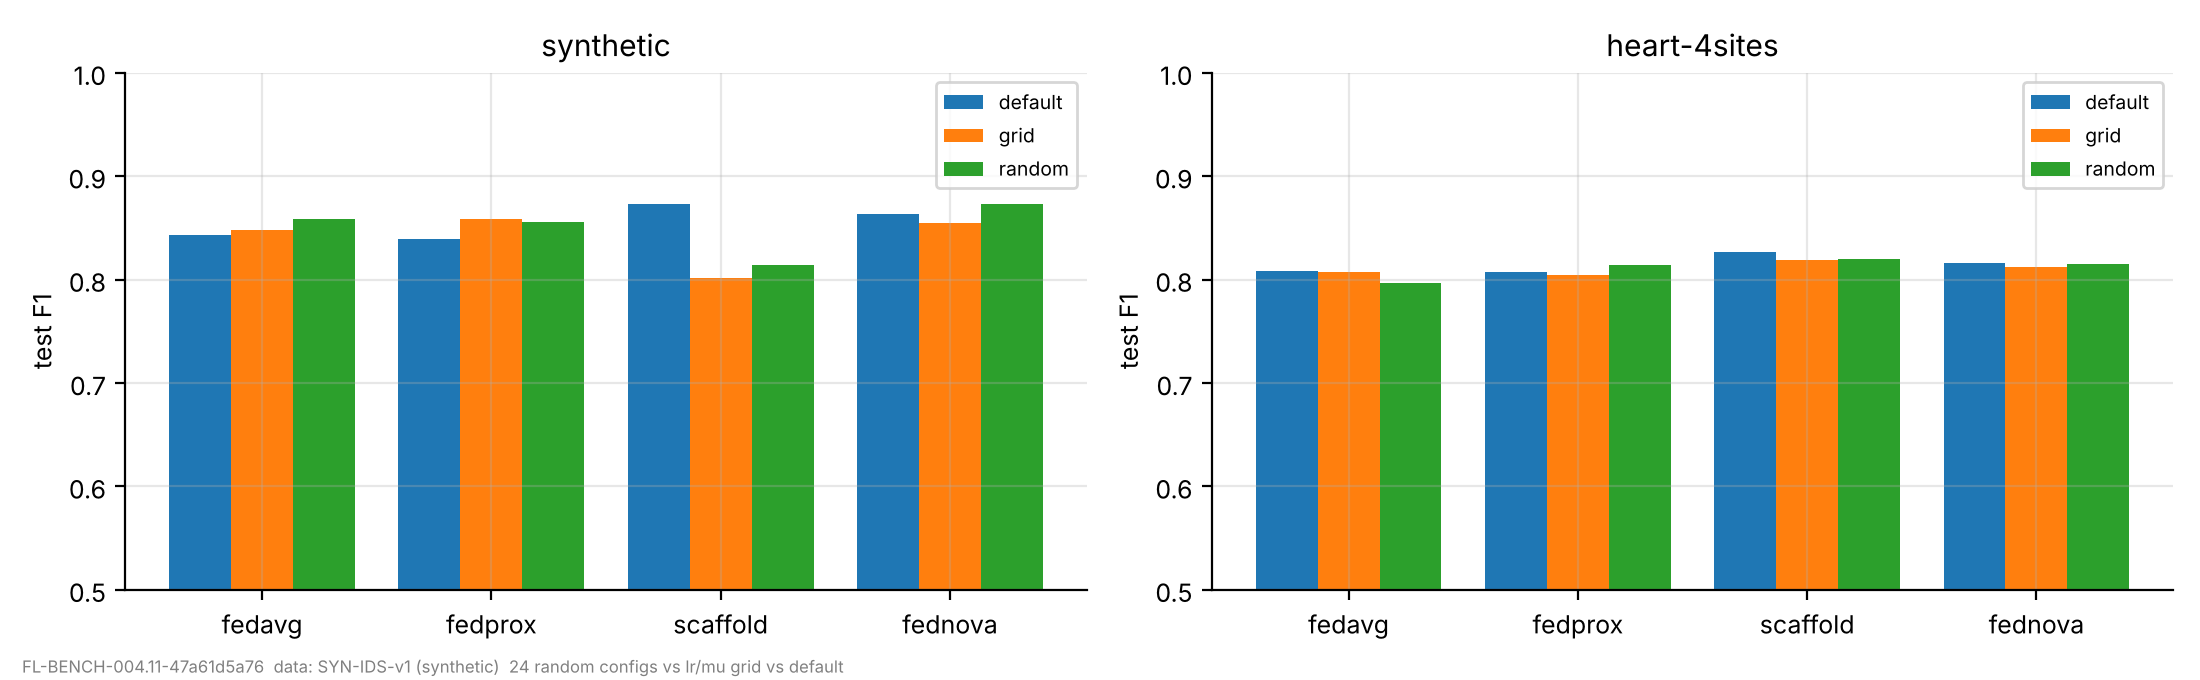

In [10]:
show_fig('task_4_11_random_search.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Budgets are matched in number of configurations, not in compute (local epochs and hidden width change cost).

In [11]:
show_csv('task_4_11_selected_configs.csv', 40)

,dataset,algo,method,lr,mu,local_epochs,batch_size,hidden,server_lr,split
0,synthetic,fedavg,"grid(lr,mu)",0.8000,0.0000,2.0,NaN,NaN,NaN,NaN
1,synthetic,fedavg,random(6 params),0.7819,0.0000,3.0,64.0,32.0,1.0,NaN
2,synthetic,fedprox,"grid(lr,mu)",0.4000,0.0100,2.0,NaN,NaN,NaN,NaN
3,synthetic,fedprox,random(6 params),0.3150,0.0138,5.0,32.0,32.0,1.0,NaN
4,synthetic,scaffold,"grid(lr,mu)",0.1000,0.0000,2.0,NaN,NaN,NaN,NaN
5,synthetic,scaffold,random(6 params),0.0194,0.0000,3.0,16.0,64.0,1.5,NaN
6,synthetic,fednova,"grid(lr,mu)",0.8000,0.0000,2.0,NaN,NaN,NaN,NaN
7,synthetic,fednova,random(6 params),0.1078,0.0000,3.0,32.0,64.0,1.0,NaN
8,heart-4sites,fedavg,"grid(lr,mu)",0.1000,0.0000,NaN,NaN,NaN,NaN,0.0
9,heart-4sites,fedavg,random(6 params),0.2856,0.0000,2.0,64.0,32.0,1.0,0.0


## 16. Limitations
- 24 configurations is a small search budget.
- Selection on small validation sets can overfit (heart: about 160 validation rows).
- Compute is not matched across configurations.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md.

**Jira acceptance:** see `docs/fl_bench_004/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`li2021niid`, `hsu2019`, `li2020fedprox`, `karimireddy2020`, `wang2020fednova` — details in `docs/fl_bench_004/references.md`.